# 1.0 Exploratory data analysis: iPhone asking prices on Tori

**Purpose.** Understand the cleaned data before modelling: how asking prices behave, what drives them, and what could mislead a model. The charts and takeaways here feed the report and back up the modelling choices (log price, which features, retailers, fairness check).

**Data.** `data/processed/iphones_clean.csv`: 2,007 for-sale iPhone listings collected from Tori.fi on 17 Sep 2026 and cleaned by `priced_right/preprocess.py`. Field definitions: [docs/data-dictionary.md](../docs/data-dictionary.md).

**How to run.** From the repo root, `uv run jupyter lab`, open this notebook, then *Run All*. It only reads data; nothing is written.

**Key terms**
- **Asking price.** What the seller asks, not what the phone sold for. Tori never shows sale prices.
- **Relative price (`rel_price`).** A listing's price ÷ the median price of the *same model*. 1.0 = typical for that model, 0.7 = 30% below. We use it to compare condition, sellers, regions and text mentions fairly: an iPhone 15 is always pricier than an iPhone 8, so raw prices mostly show the model.
- **Condition labels** (Tori, Finnish): *Uusi* = new, *Kuin uusi* = like new, *Hyvä* = good, *Kohtalainen* = fair, *Vaatii korjausta* = needs repair.

**Contents.** 1 Overview · 2 Target · 3 Model and storage · 4 Condition · 5 Seller type · 6 Region · 7 Text mentions and battery · 8 Correlations · 9 Duplicates and outliers · 10 Summary

## 0. Setup

**What:** load the cleaned data and add three helper columns.
**Why:** `log_price` is what the models predict; `rel_price` compares listings within the same model; `is_private` turns seller type into a number for correlations (the team's first-look notebook did the same).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from priced_right.evaluate import load_clean  # same loader the models use, so paths work from anywhere

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30, "display.width", 120)

df = load_clean()
df["log_price"] = np.log1p(df["price_eur"])
df["rel_price"] = df["price_eur"] / df.groupby("exact_model")["price_eur"].transform("median")
df["is_private"] = df["seller_type"].eq("private")

print(f"{len(df):,} listings, {df['exact_model'].nunique()} models, collected {df['collected_at'].iloc[0][:10]}")

2,007 listings, 51 models, collected 2026-09-17


## 1. Overview

**What:** column types, missing values and distinct values; summary statistics of the numeric columns.
**Why:** to know what we can rely on before drawing conclusions. Missing values need a plan in the models.

In [2]:
pd.DataFrame({
    "type": df.dtypes.astype(str),
    "missing %": df.isna().mean().mul(100).round(1),
    "distinct": df.nunique(),
})

,type,missing %,distinct
listing_id,str,0.0,2007
price_eur,int64,0.0,284
title,str,0.0,1660
description,str,0.0,1972
exact_model,str,0.0,51
model_group,str,0.0,8
model_group_filled,bool,0.0,2
release_year,int64,0.0,18
storage_gb,float64,3.7,9
condition,str,3.4,5


In [3]:
df[["price_eur", "storage_gb", "release_year", "battery_pct", "listing_age_days"]].describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
price_eur,2007.0,330.3,273.4,6.0,130.0,250.0,450.0,2299.0
storage_gb,1932.0,157.3,133.8,8.0,64.0,128.0,256.0,2048.0
release_year,2007.0,2020.8,2.7,2008.0,2019.0,2021.0,2023.0,2026.0
battery_pct,1029.0,87.5,9.1,54.0,80.0,86.0,97.0,100.0
listing_age_days,2007.0,28.7,53.6,0.0,3.0,14.0,40.0,587.0


**Takeaway:** almost every column is complete. Only `battery_pct` is often missing (49%), because half of the sellers don't mention battery health. `storage_gb` (4%) and `condition` (3%) are rarely missing. The models keep "missing" as its own value instead of dropping rows.

## 2. Target: asking price

**What:** the distribution of asking prices, raw and on a log scale.
**Why:** a long tail of expensive phones would dominate squared-error metrics. If the log scale looks more balanced, we model log price (and score with RMSLE).

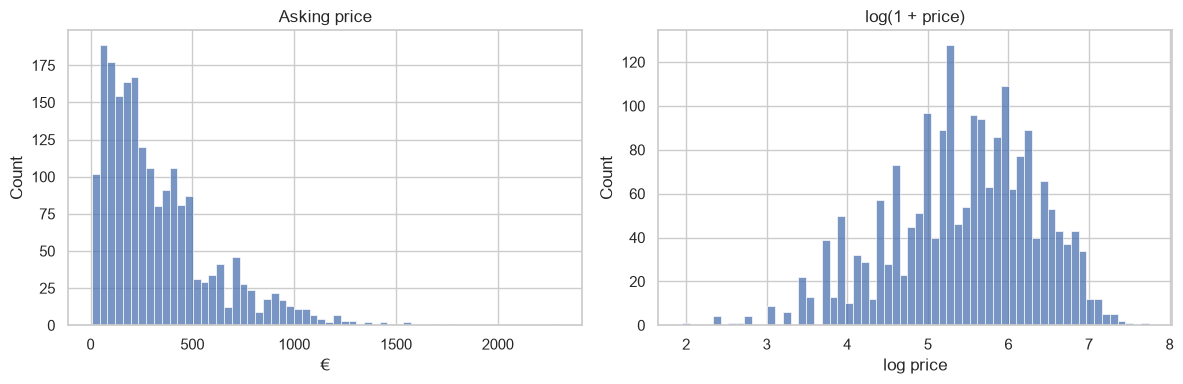

median 250 €, mean 330 € | skewness: raw 1.57, log -0.46


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price_eur"], bins=60, ax=axes[0]).set(title="Asking price", xlabel="€")
sns.histplot(df["log_price"], bins=60, ax=axes[1]).set(title="log(1 + price)", xlabel="log price")
plt.tight_layout()
plt.show()
print(f"median {df['price_eur'].median():.0f} €, mean {df['price_eur'].mean():.0f} € | "
      f"skewness: raw {df['price_eur'].skew():.2f}, log {df['log_price'].skew():.2f}")

**Takeaway:** raw prices are right-skewed (skewness 1.57; mean 330 € vs median 250 €). A few new Pro Max phones sit far above the many older models. On the log scale the skew almost disappears (−0.46), which supports training on `log1p(price)` and reporting RMSLE.

## 3. Model and storage

**What:** price by model, price by storage within the most common models, and how much prices spread within each model.
**Why:** model should be the strongest driver. The spread answers the canvas question of whether phone prices are predictable, and shows where the model will struggle.

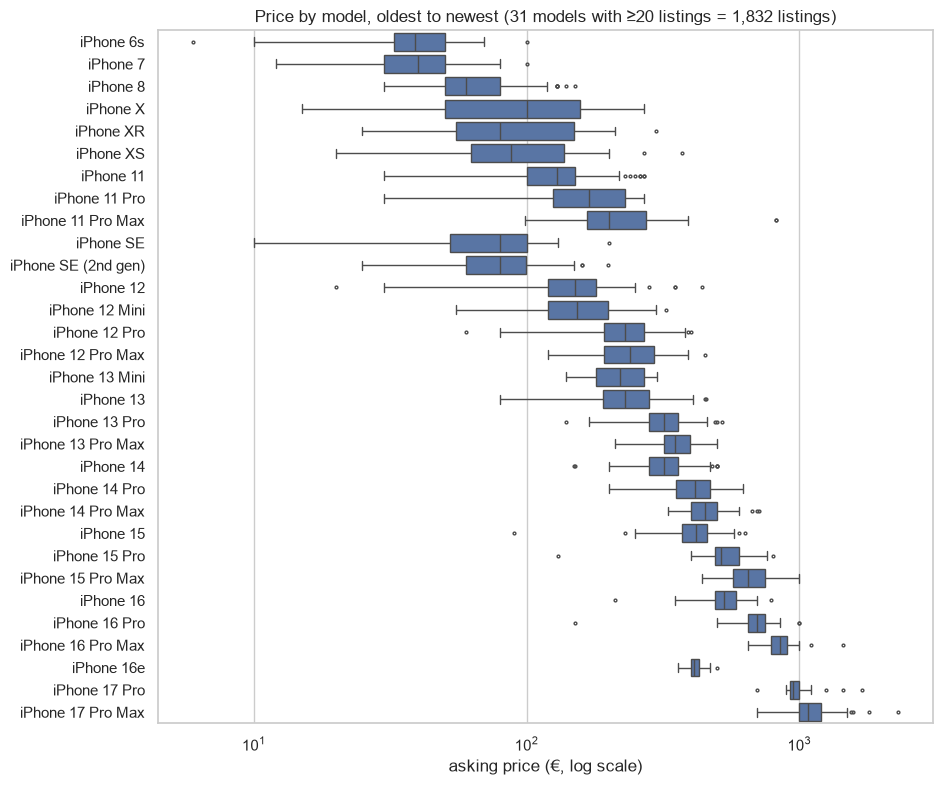

In [5]:
counts = df["exact_model"].value_counts()
common = counts[counts >= 20].index  # enough listings for a stable box plot
order = (df[df["exact_model"].isin(common)]
         .groupby("exact_model").agg(year=("release_year", "first"), median=("price_eur", "median"))
         .sort_values(["year", "median"]).index)

fig, ax = plt.subplots(figsize=(10, 9))
sns.boxplot(data=df[df["exact_model"].isin(common)], y="exact_model", x="price_eur", order=order, fliersize=2, ax=ax)
ax.set(xscale="log", xlabel="asking price (€, log scale)", ylabel="",
       title=f"Price by model, oldest to newest ({len(common)} models with ≥20 listings = {counts[common].sum():,} listings)")
plt.show()

In [6]:
# Median price (€) by storage for the 8 most common models; empty = no listings
top = counts.head(8).index
(df[df["exact_model"].isin(top)]
 .pivot_table(index="exact_model", columns="storage_gb", values="price_eur", aggfunc="median")
 .reindex(top).round(0))

storage_gb,32.0,64.0,128.0,256.0,512.0,1024.0
exact_model,,,,,,
iPhone 13,NaN,160.0,219.0,290.0,324.0,NaN
iPhone 11,NaN,120.0,145.0,150.0,NaN,NaN
iPhone 12,NaN,145.0,169.0,130.0,NaN,NaN
iPhone 15,NaN,NaN,415.0,462.0,NaN,NaN
iPhone 14,NaN,NaN,320.0,338.0,484.0,NaN
iPhone 13 Pro,NaN,NaN,300.0,325.0,404.0,455.0
iPhone 12 Mini,120.0,159.0,154.0,240.0,NaN,NaN
iPhone 15 Pro,NaN,NaN,500.0,600.0,550.0,NaN


In [7]:
# Spread within a model: interquartile range (IQR) as a share of the median. 0.1 = tight, 1.0 = very wide
spread = (df[df["exact_model"].isin(common)].groupby("exact_model")["price_eur"]
          .agg(listings="size", median="median", iqr=lambda s: s.quantile(0.75) - s.quantile(0.25)))
spread["iqr / median"] = (spread["iqr"] / spread["median"]).round(2)
spread.sort_values("iqr / median")

,listings,median,iqr,iqr / median
exact_model,,,,
iPhone 16e,25,410.0,30.00,0.07
iPhone 17 Pro,30,950.0,77.25,0.08
iPhone 16 Pro Max,52,850.0,112.50,0.13
iPhone 16 Pro,54,699.5,100.00,0.14
iPhone 16,52,529.0,93.50,0.18
iPhone 17 Pro Max,61,1079.0,200.00,0.19
iPhone 15,104,419.5,89.00,0.21
iPhone 15 Pro,66,515.0,111.50,0.22
iPhone 13 Pro Max,38,350.0,76.75,0.22


**Takeaway:** price rises steadily with release year, from under 100 € for iPhone X/XR to around 950 € for the iPhone 17 Pro. More storage usually costs more within a model (iPhone 13: 160 → 220 → 290 → 324 € from 64 to 512 GB), though small groups are noisy (iPhone 12 at 256 GB). **Spread differs a lot by age:** new models have tight prices (IQR under 15% of the median for the iPhone 16e and 17 Pro), while old ones vary as much as their median (X, XR, XS). For old phones, condition and battery matter more than the model name, so the model will be least accurate there.

**iPhone SE generations** differ a lot: the 3rd generation (2022) has a median of 175 €, the 2nd (2020) 80 € and the 1st (2016) 33 €. Cleaning keeps them apart when the ad says which one (30 SE ads don't).

## 4. Condition

**What:** relative price (price ÷ same-model median) for each condition label.
**Why:** using relative price removes the model effect, so we see the pure effect of condition.

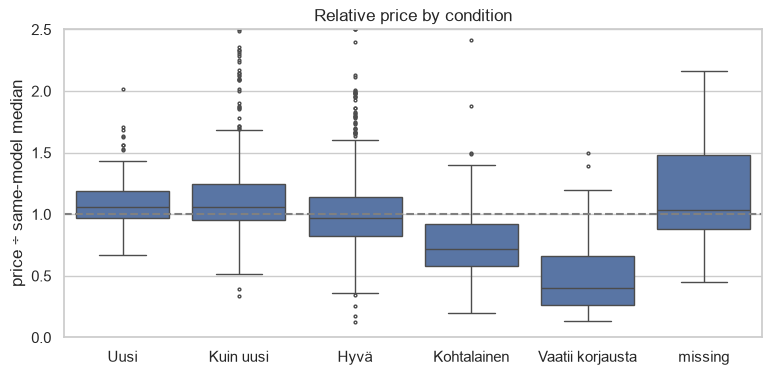

,listings,median
condition,,
Uusi,107,1.06
Kuin uusi,684,1.06
Hyvä,953,0.97
Kohtalainen,151,0.72
Vaatii korjausta,44,0.40
missing,68,1.04


In [8]:
cond_order = ["Uusi", "Kuin uusi", "Hyvä", "Kohtalainen", "Vaatii korjausta", "missing"]
d = df.assign(condition=df["condition"].fillna("missing"))

fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=d, x="condition", y="rel_price", order=cond_order, fliersize=2, ax=ax)
ax.axhline(1, ls="--", c="grey")
ax.set(ylim=(0, 2.5), xlabel="", ylabel="price ÷ same-model median", title="Relative price by condition")
plt.show()
d.groupby("condition")["rel_price"].agg(listings="size", median="median").reindex(cond_order).round(2)

**Takeaway:** condition matters mainly at the bottom. *Fair* sells about 30% below the model's median (0.72) and *needs repair* about 60% below (0.40). *New* (1.06), *like new* (1.06) and *good* (0.97) are close together, so sellers use the top labels loosely. Listings without a condition price about normally (1.04).

## 5. Seller type

**What:** private sellers vs retailers: counts, prices, and relative prices.
**Why:** retailers are 22% of the data and may price differently. This informs the open group decision on whether to keep them.

In [9]:
df.groupby("seller_type").agg(
    listings=("price_eur", "size"),
    median_price=("price_eur", "median"),
    median_rel_price=("rel_price", "median"),
    median_release_year=("release_year", "median"),
).round(2)

,listings,median_price,median_rel_price,median_release_year
seller_type,,,,
private,1573,220.0,0.96,2021.0
retailer,434,340.0,1.23,2021.0


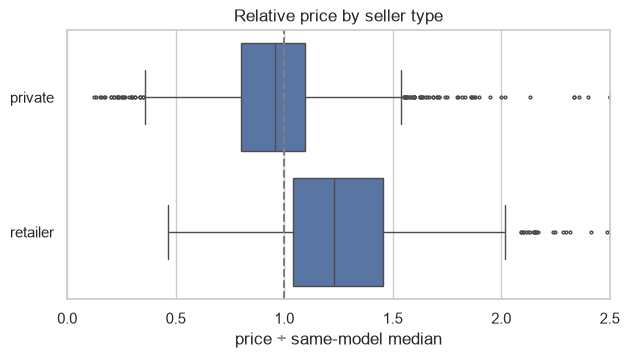

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.boxplot(data=df, x="rel_price", y="seller_type", fliersize=2, ax=ax)
ax.axvline(1, ls="--", c="grey")
ax.set(xlim=(0, 2.5), xlabel="price ÷ same-model median", ylabel="", title="Relative price by seller type")
plt.show()

**Takeaway:** for the same model, retailers ask about **28% more** than private sellers (median relative price 1.23 vs 0.96), although both sell phones of the same median age (2021). This is a strong, real effect (warranty, refurbishing, returns), so `seller_type` must stay a model feature. We recommend keeping retailers **with** that feature rather than dropping 22% of the data.

## 6. Region

**What:** listings and median relative price per region.
**Why:** the fairness check compares model errors by region. Regions with few listings can't be judged reliably, and differences may come from who sells there rather than where.

In [11]:
region = (df.groupby("region")
          .agg(listings=("price_eur", "size"),
               share_pct=("price_eur", lambda s: round(len(s) / len(df) * 100, 1)),
               retailer_share=("seller_type", lambda s: (s == "retailer").mean()),
               median_rel_price=("rel_price", "median"))
          .sort_values("listings", ascending=False))
region.round(2)

,listings,share_pct,retailer_share,median_rel_price
region,,,,
Uusimaa,933,46.5,0.28,1.00
Pirkanmaa,195,9.7,0.16,0.98
Varsinais-Suomi,190,9.5,0.19,1.00
Pohjanmaa,99,4.9,0.79,1.35
Pohjois-Pohjanmaa,90,4.5,0.13,1.00
Keski-Suomi,77,3.8,0.00,0.93
Päijät-Häme,63,3.1,0.00,1.00
Pohjois-Savo,56,2.8,0.00,0.94
Satakunta,46,2.3,0.00,0.95


**Takeaway:** almost half the listings are in Uusimaa (933), and most regions price close to typical (0.92–1.01; Lappi a little lower at 0.88). **Pohjanmaa stands out (1.35), but only because 79% of its listings come from a retailer**: its private sellers ask *below* typical (0.78). Region effects are mostly seller effects. Kainuu (8) and Keski-Pohjanmaa (3) are too small for any regional conclusion, so the fairness check should group or flag them.

## 7. Text mentions and battery

**What:** relative price with vs without each mention (warranty, receipt, box, damage, shipping), and by battery health.
**Why:** these come from free text and are cheap to extract. If they move price, they're worth keeping as features and explaining in the report.

In [12]:
flags = ["mentions_warranty", "mentions_receipt", "mentions_box", "mentions_damage", "shipping_available"]
rows = []
for flag in flags:
    medians = df.groupby(flag)["rel_price"].median()
    rows.append({"feature": flag, "listings with it %": round(df[flag].mean() * 100, 1),
                 "median rel. price with": round(medians.get(True, np.nan), 2),
                 "without": round(medians.get(False, np.nan), 2)})
pd.DataFrame(rows).set_index("feature")

,listings with it %,median rel. price with,without
feature,,,
mentions_warranty,20.7,1.09,0.98
mentions_receipt,4.3,0.98,1.00
mentions_box,13.2,1.00,1.00
mentions_damage,14.8,0.85,1.00
shipping_available,37.3,0.98,1.01


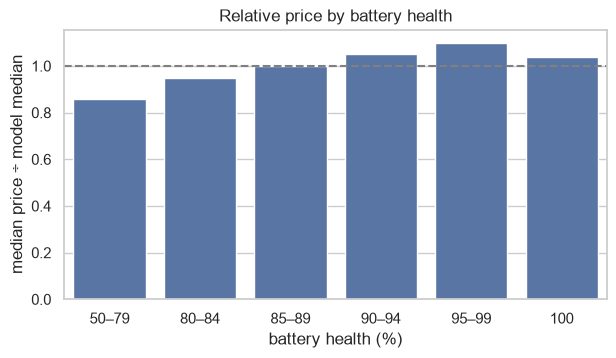

,listings,median
battery_pct,,
50–79,230,0.86
80–84,171,0.95
85–89,209,1.00
90–94,120,1.05
95–99,67,1.10
100,232,1.04


In [13]:
b = df.dropna(subset=["battery_pct"])
bands = pd.cut(b["battery_pct"], [49, 79, 84, 89, 94, 99, 100], labels=["50–79", "80–84", "85–89", "90–94", "95–99", "100"])
battery = b.groupby(bands, observed=True)["rel_price"].agg(listings="size", median="median").round(2)

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.barplot(x=battery.index.astype(str), y=battery["median"], color="C0", ax=ax)
ax.axhline(1, ls="--", c="grey")
ax.set(xlabel="battery health (%)", ylabel="median price ÷ model median", title="Relative price by battery health")
plt.show()
battery

**Takeaway:** **damage mentions** cut the price by about 15% (0.85) and **warranty mentions** add about 11% (1.09 vs 0.98; partly because retailers mention warranty). Receipt, box and shipping make little difference. **Battery health** has a clear effect: below 80% sells about 14% under typical (0.86), 95–99% about 10% above (1.10). 100% is a little lower (1.04), likely a mix of new phones and cheap older phones with a replaced battery. Battery is known for only half of the listings, so it helps where present.

## 8. Correlations

**What:** the team's correlation heatmap, redone as **Spearman** correlations with **log price**.
**Why:** Spearman compares rankings, so it isn't thrown off by skewed prices or yes/no columns. Note: raw correlations mix up effects. For example, battery % partly tracks phone age, so sections 4–7 (relative price) are the fairer view.

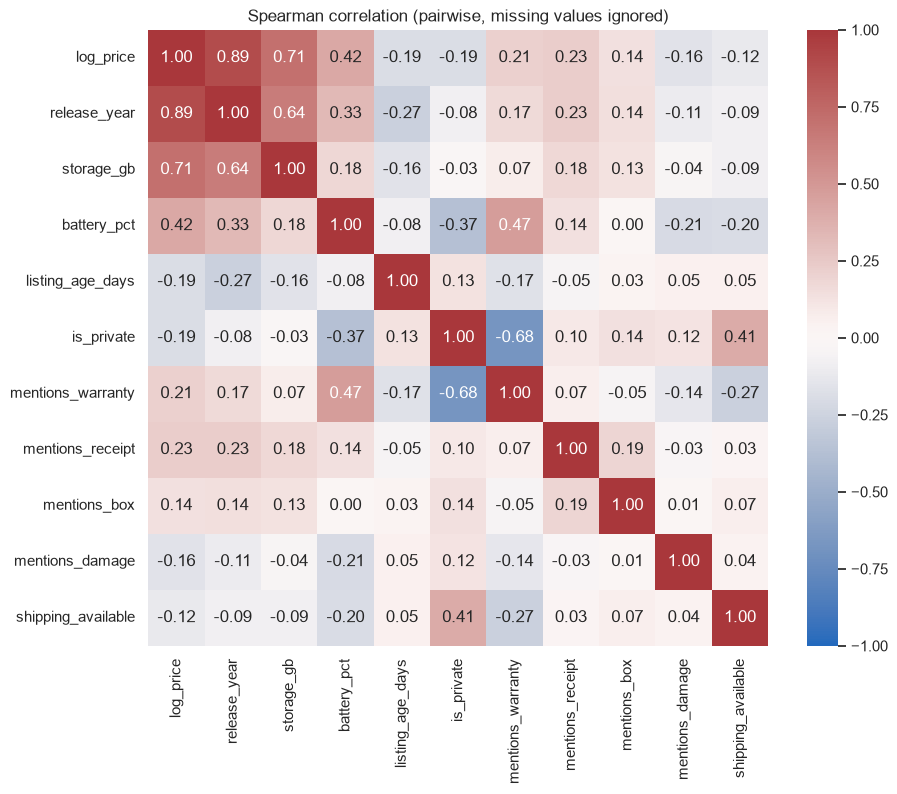

In [14]:
cols = ["log_price", "release_year", "storage_gb", "battery_pct", "listing_age_days", "is_private",
        "mentions_warranty", "mentions_receipt", "mentions_box", "mentions_damage", "shipping_available"]
corr = df[cols].astype(float).corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation (pairwise, missing values ignored)")
plt.show()

**Takeaway:** **release year (0.89)** and **storage (0.71)** dominate, which is why the median by model + storage is already a strong baseline. Battery (0.42) comes next. Warranty and receipt (≈0.2) are positive, while private seller, damage, listing age and shipping (−0.12 to −0.19) are negative. Warranty and private seller are strongly linked (−0.68): warranty mentions come mostly from retailers, so the two effects overlap. Older listings are cheaper; they may be overpriced ones that don't sell, or simply older phones.

## 9. Duplicates and outliers

**What:** ads posted more than once, and listings priced far from their model's median.
**Why:** duplicates can leak between training and test (handled by grouped cross-validation), and extreme prices often reveal cleaning mistakes rather than real prices.

In [15]:
sizes = df["relisting_group"].value_counts()
repeated = sizes[sizes > 1]
print(f"{len(repeated)} ads appear more than once ({repeated.sum()} listings); by seller:",
      df[df["relisting_group"].isin(repeated.index)]["seller_type"].value_counts().to_dict())

29 ads appear more than once (67 listings); by seller: {'retailer': 61, 'private': 6}


In [16]:
extreme = df[(df["rel_price"] > 3) | (df["rel_price"] < 0.25)]
print(f"{len(extreme)} listings under 25% or over 300% of their model's median")
extreme.sort_values("rel_price")[["price_eur", "rel_price", "exact_model", "condition", "seller_type", "title"]].round(2)

20 listings under 25% or over 300% of their model's median


,price_eur,rel_price,exact_model,condition,seller_type,title
572,10,0.12,iPhone SE,Hyvä,private,Apple iPhone SE puhelin
692,20,0.13,iPhone 12,Vaatii korjausta,private,Rikkinäinen iphone 12
1845,15,0.15,iPhone X,Vaatii korjausta,private,Iphone X
818,6,0.15,iPhone 6s,Vaatii korjausta,private,"iPhone 6S, viallinen"
1201,15,0.17,iPhone 4s,Hyvä,private,iPhone 4S
638,30,0.18,iPhone 11 Pro,Vaatii korjausta,private,iPhone 11 Pro 128 GB
1042,10,0.20,iPhone 6s Plus,Kohtalainen,private,iphone 6S Plus (32GB Ehkä)
18,30,0.20,iPhone 12,Vaatii korjausta,private,Apple iPhone 12 64 GB sininen
830,150,0.21,iPhone 16 Pro,Vaatii korjausta,private,Apple iPhone 16Pro128 GB
796,90,0.21,iPhone 15,Vaatii korjausta,private,iPhone 15 128 Gt – rikkinäinen / korjattavaksi


**Takeaway:** 29 ads appear more than once (67 listings, 61 of them retailers' template ads). GroupKFold keeps each group in one fold, so they can't leak. The 20 remaining extreme prices look genuine: broken phones at the low end, and retailer premiums on old models or large storage at the high end (e.g. an iPhone 11 Pro Max at 820 €). We keep them; log price limits their influence.

**Cleaning issues this section first surfaced, now fixed in `preprocess.py`** (see the funnel in [docs/results.md](../docs/results.md)):
1. **Storage read as a model:** "iPhone 16 GB" is 16 GB of storage, not the iPhone 16.
2. **Spare parts at any price** (3 removed), e.g. an original rear camera (*takakamera*) or screens (*näyttöjä*) above the 40 € accessory cut-off.
3. **Bundles** (6 removed): several models in one title ("iPhone 12/ 12 pro max", "iPhone 13 ja iphone 11"), or an iPhone sold with an Apple Watch, iPad or Android phones.
4. **iPhone SE generations split:** 1st (2016), 2nd (2020) and 3rd (2022) were one "iPhone SE" model; see section 3.

## 10. Summary

**What drives asking price** (strongest first):
1. **Model / release year** and **storage**: the baseline "median by model + storage" already captures most of it.
2. **Seller type:** retailers ask about 28% more for the same model.
3. **Condition:** only *fair* (−30%) and *needs repair* (−60%) differ much; the top three labels are used loosely.
4. **Battery health** (known for half the listings): about −14% below 80%, about +10% at 95–99%.
5. **Text mentions:** damage −15%, warranty +11%; receipt, box and shipping make little difference.

**What this means for the models**
- Keep log price and RMSLE (section 2).
- Keep retailers, with `seller_type` as a feature (section 5).
- Old models vary much more than new ones; expect bigger errors there, and wider MAPIE price ranges (section 3).
- Regional differences mostly reflect seller mix, so the fairness check should compare errors by region **and** seller type, and group tiny regions (section 6).

**Next steps**
- Add Random Forest to `models.py` and compare it with Ridge (`uv run python -m priced_right.models`).
- Keyword–price associations (canvas): the largest Ridge TF-IDF coefficients, in a `2.0-models` notebook.